In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
from scipy.optimize import curve_fit
from scipy.integrate import cumulative_trapezoid
import pandas as pd
import cmcrameri.cm as cm
from matplotlib.patches import Rectangle
from matplotlib.patches import Polygon

import analysis_functions as afn

In [2]:
with Image.open('data_shot3_raw/streak/z4290leg1_laserstreak_preshot-nr.tif') as img:
    streak_pre_nr = np.array(img)
with Image.open('data_shot3_raw/streak/z4290leg1_laserstreak_preshot-r.tif') as img:
    streak_pre_r = np.array(img)   
with Image.open('data_shot3_raw/streak/z4290leg1_laserstreak.tif') as img:
    streak = np.array(img)   

calib = pd.read_csv('streak_calib.csv')

In [3]:
px_to_mm = calib['value'].values[0]
px_to_ns = calib['value'].values[1]
print(px_to_ns*3)

calib_factors = [px_to_ns, px_to_mm]

cmax = np.percentile(streak, 99)

0.1004481480808545


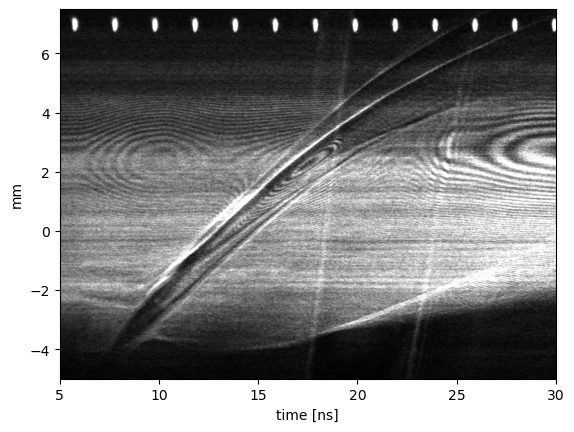

In [4]:
fig, ax = plt.subplots()

extent_x = streak.shape[1] * px_to_ns
extent_y = streak.shape[0] * px_to_mm
ext=[0, extent_x, -extent_y/2, extent_y/2]

plt.imshow(streak, cmap = 'grey', extent=ext, aspect='auto')
plt.clim(0, cmax)
plt.xlabel('time [ns]')
plt.ylabel('mm')

plt.xlim(5, 30)
# plt.xlim(18, 24)
plt.ylim(-5,7.5)

plt.savefig('streak_images/zfs/streak_zoom.jpg', bbox_inches = 'tight')

In [5]:
times_bkgd = np.linspace(3, 5, 51)
times_bkgd = np.array(times_bkgd)
pos_bkgd, lineouts_bkgd = afn.get_lineouts(streak, times_bkgd, bg = np.array([0,0]), cf = calib_factors, ext = ext)

mask = (times_bkgd > 4.0) | (times_bkgd < 3.5)
times_bkgd = times_bkgd[mask]
pos_bkgd = pos_bkgd[mask]
lineouts_bkgd = lineouts_bkgd[mask]

In [6]:
background = np.mean(lineouts_bkgd, axis = 0)

In [7]:
times_shock = np.linspace(10, 30, 21)
pos_shock, lineouts_shock = afn.get_lineouts(streak, times_shock, background, calib_factors, ext)

background subtracting...


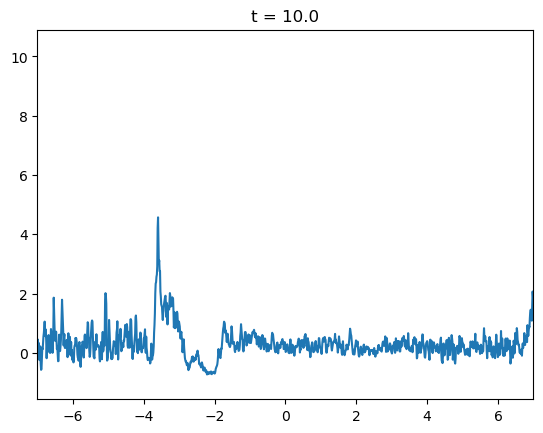

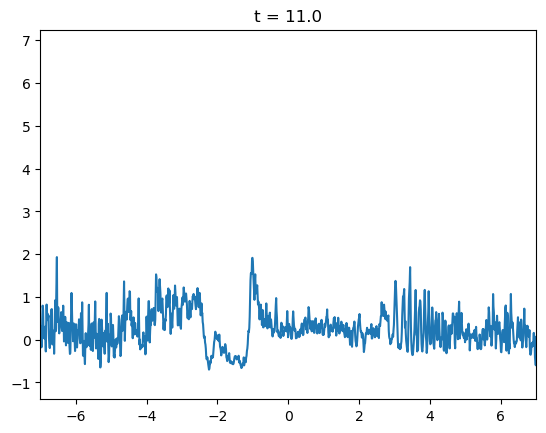

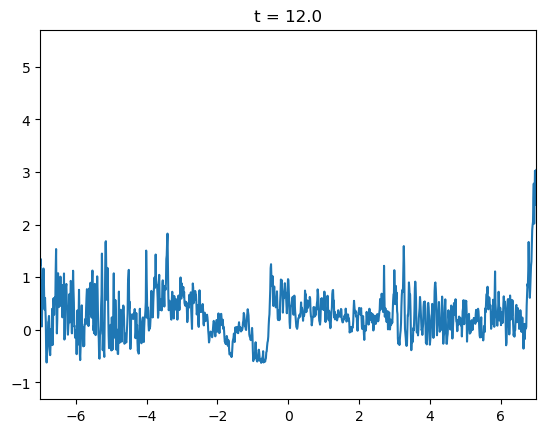

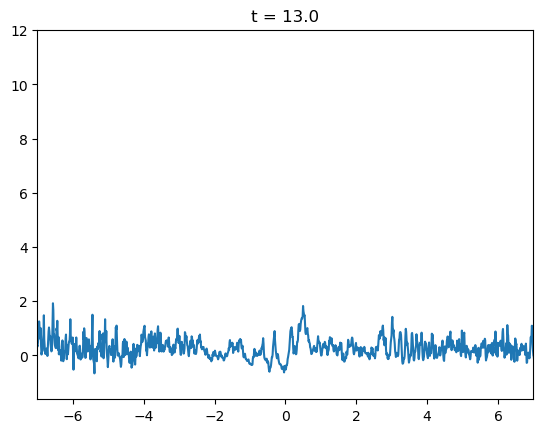

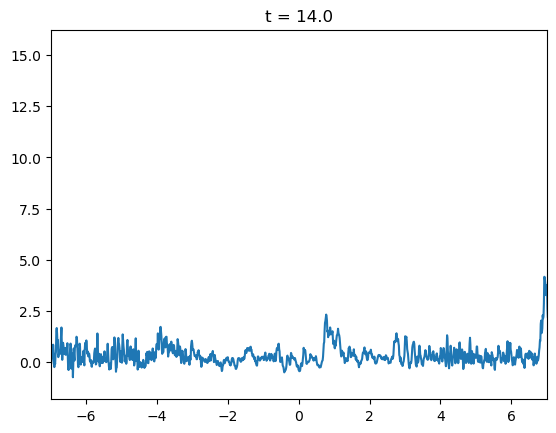

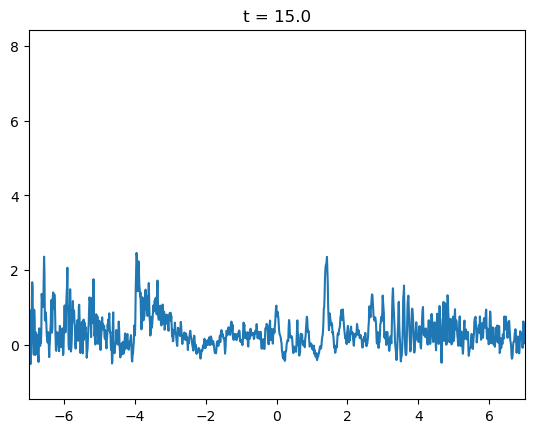

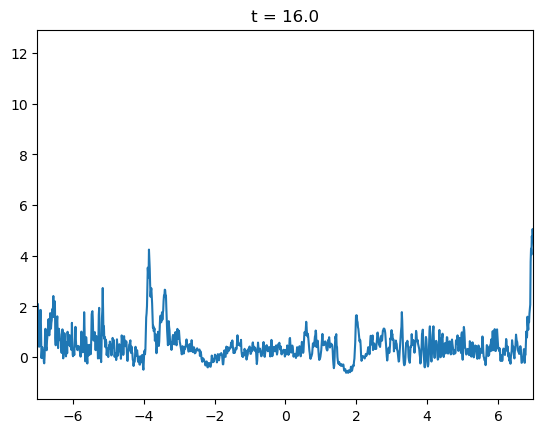

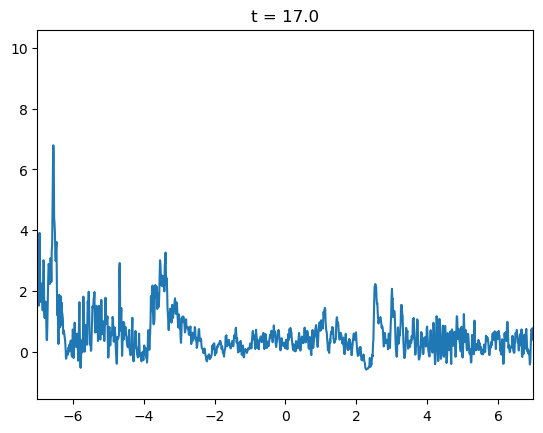

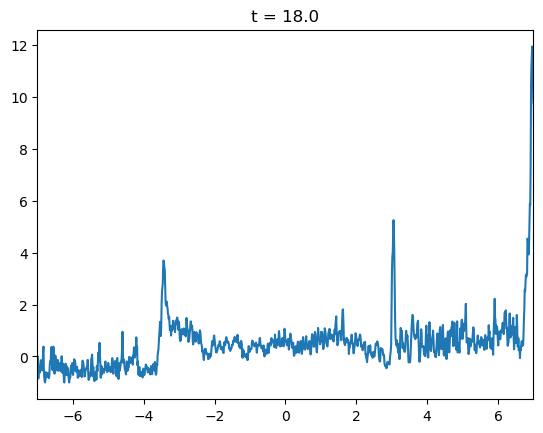

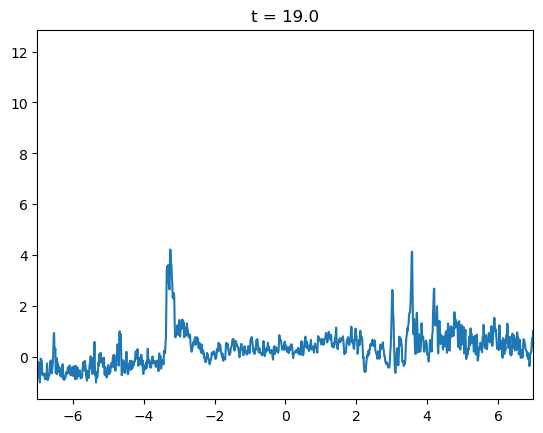

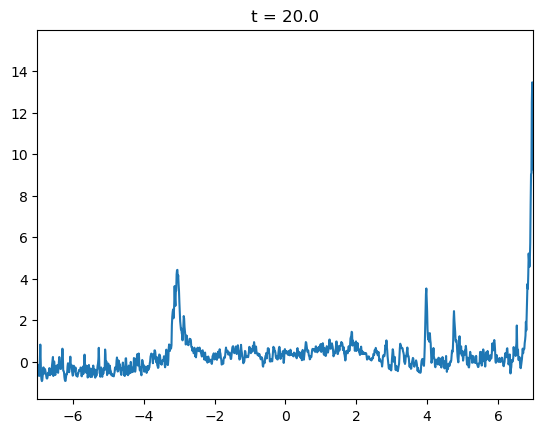

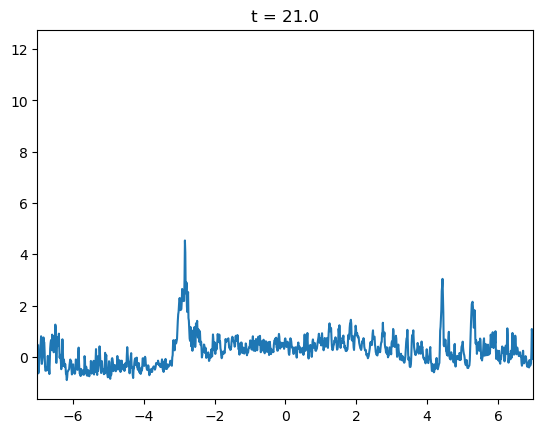

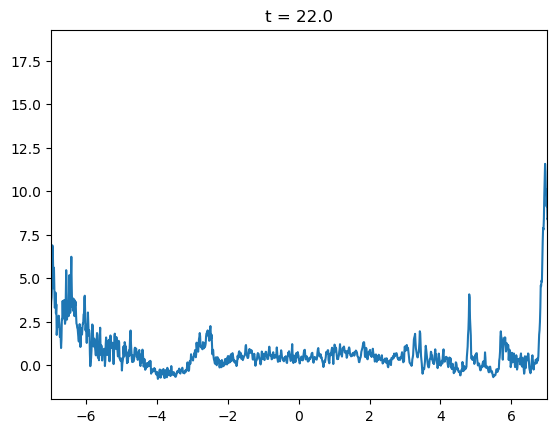

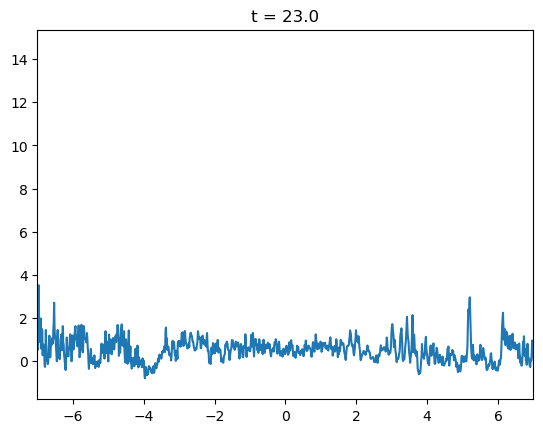

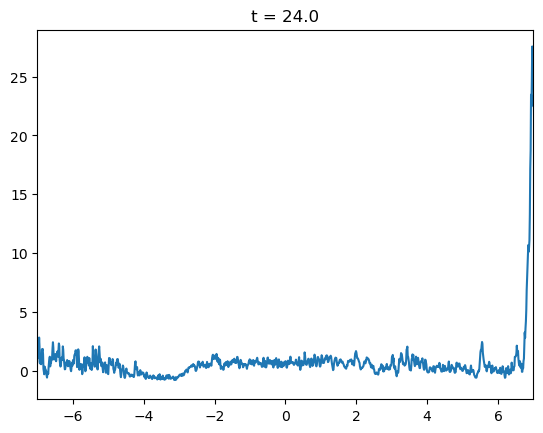

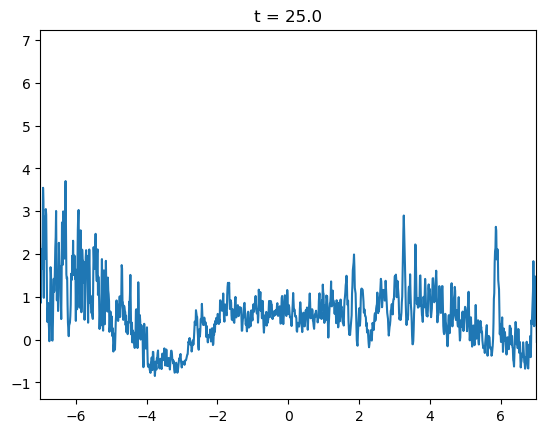

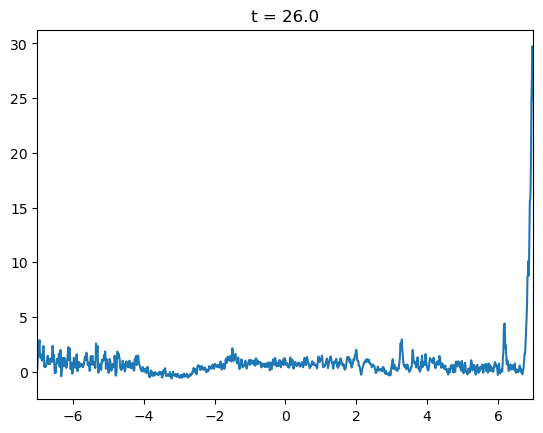

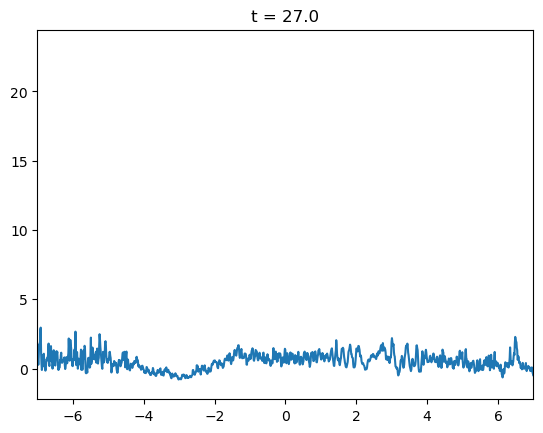

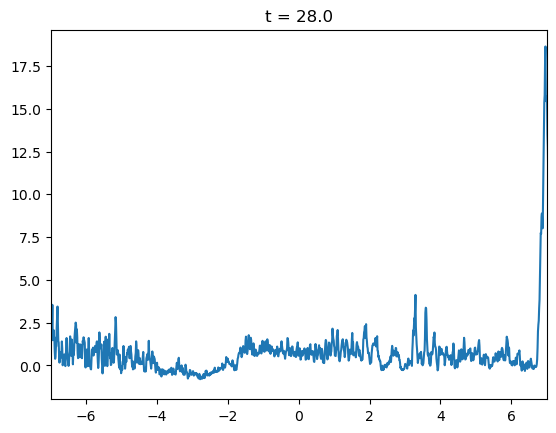

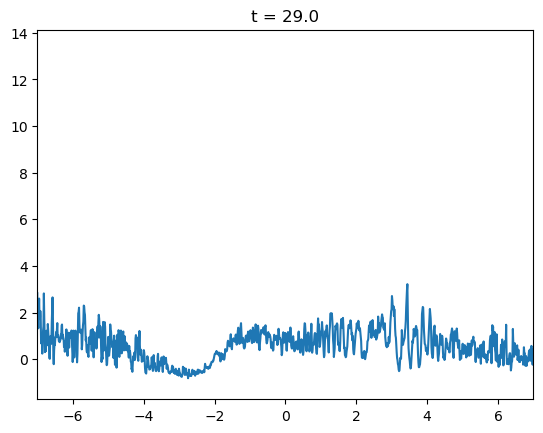

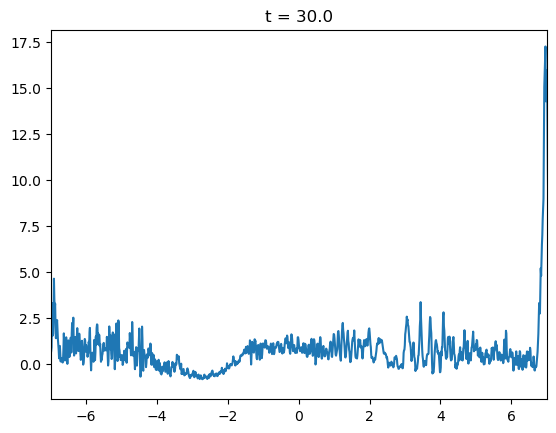

<Figure size 640x480 with 0 Axes>

In [8]:
for i in range(len(times_shock)):
    plt.plot(pos_shock[i], lineouts_shock[i])
    plt.title(f't = {times_shock[i]}')
    plt.xlim(-7,7)
    plt.show()
    plt.clf()

In [9]:
# average lineouts over 2 ns 
x_common = np.linspace(-2, 2, 1000)

times_avg_1516 = np.linspace(15, 16, 51)
pos_avg_1516, lineouts_avg_1516 = afn.get_lineouts(streak, times_avg_1516, background, calib_factors, ext)

times_avg_1617 = np.linspace(16, 17, 51)
pos_avg_1617, lineouts_avg_1617 = afn.get_lineouts(streak, times_avg_1617, background, calib_factors, ext)

times_avg_1718 = np.linspace(17, 18, 51)
pos_avg_1718, lineouts_avg_1718 = afn.get_lineouts(streak, times_avg_1718, background, calib_factors, ext)

times_avg_1819 = np.linspace(18, 19, 51)
pos_avg_1819, lineouts_avg_1819 = afn.get_lineouts(streak, times_avg_1819, background, calib_factors, ext)

times_avg_1920 = np.linspace(19, 20, 51)
pos_avg_1920, lineouts_avg_1920 = afn.get_lineouts(streak, times_avg_1920, background, calib_factors, ext)

times_avg_2021 = np.linspace(20, 21, 51)
pos_avg_2021, lineouts_avg_2021 = afn.get_lineouts(streak, times_avg_2021, background, calib_factors, ext)

times_avg_2122 = np.linspace(21, 22, 51)
pos_avg_2122, lineouts_avg_2122 = afn.get_lineouts(streak, times_avg_2122, background, calib_factors, ext)

times_avg_2223 = np.linspace(22, 23, 51)
pos_avg_2223, lineouts_avg_2223 = afn.get_lineouts(streak, times_avg_2223, background, calib_factors, ext)

times_avg_2324 = np.linspace(23, 24, 51)
pos_avg_2324, lineouts_avg_2324 = afn.get_lineouts(streak, times_avg_2324, background, calib_factors, ext)

times_avg_2425 = np.linspace(24, 25, 51)
pos_avg_2425, lineouts_avg_2425 = afn.get_lineouts(streak, times_avg_2425, background, calib_factors, ext)

background subtracting...
background subtracting...
background subtracting...
background subtracting...
background subtracting...
background subtracting...
background subtracting...
background subtracting...
background subtracting...
background subtracting...


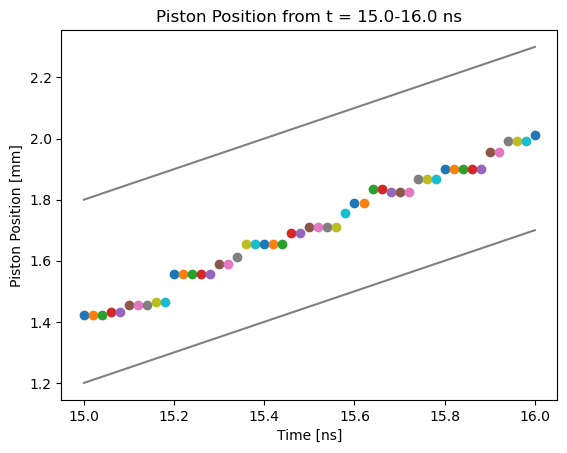

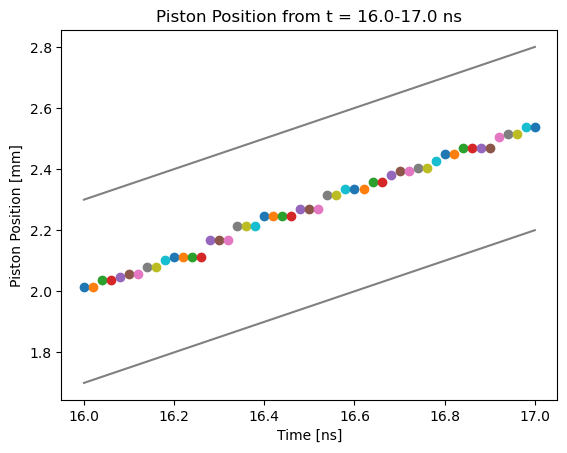

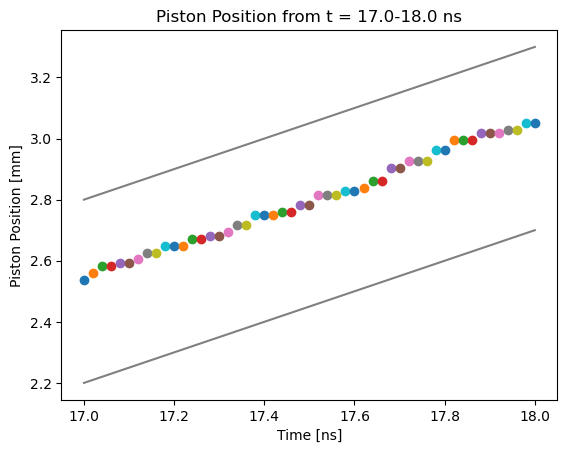

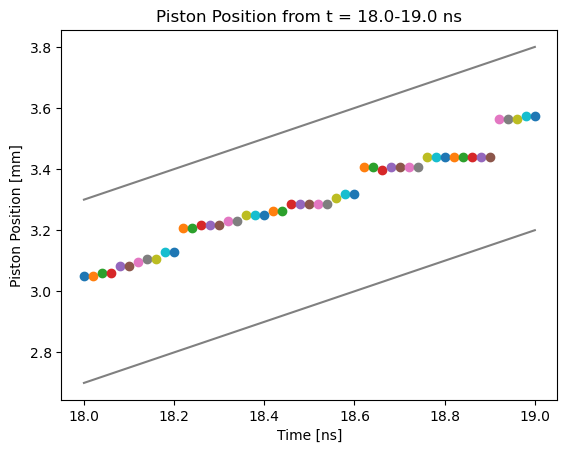

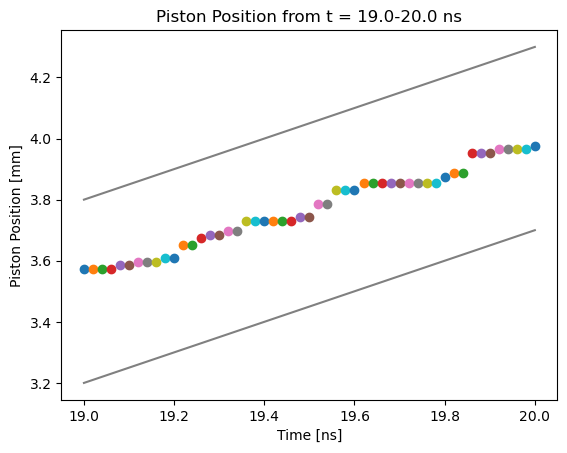

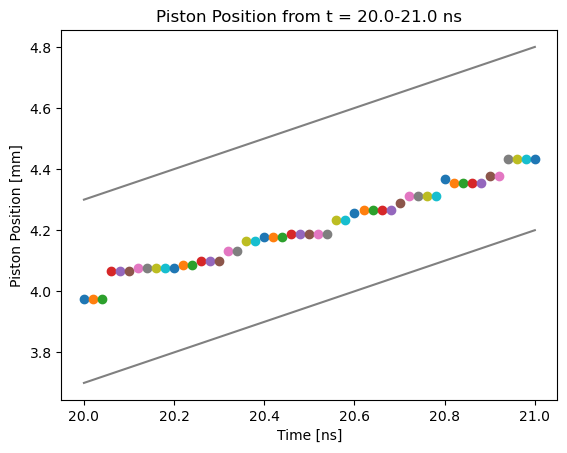

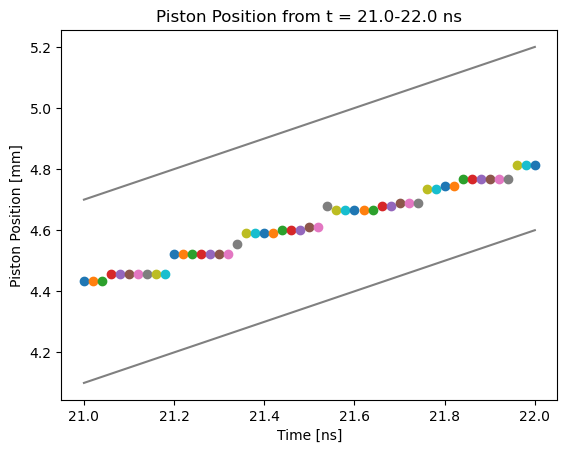

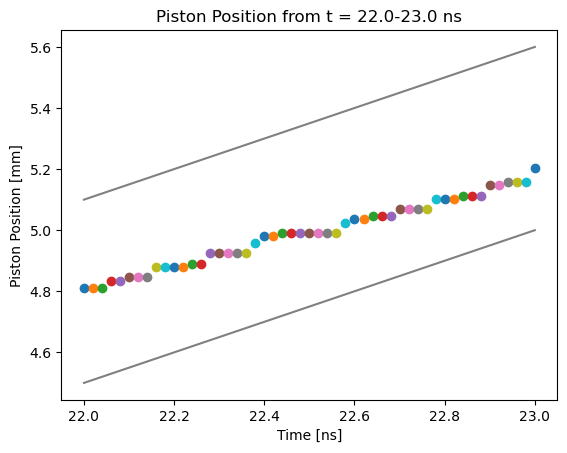

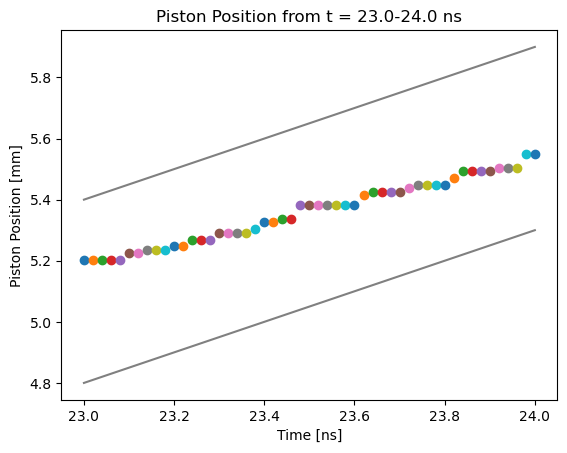

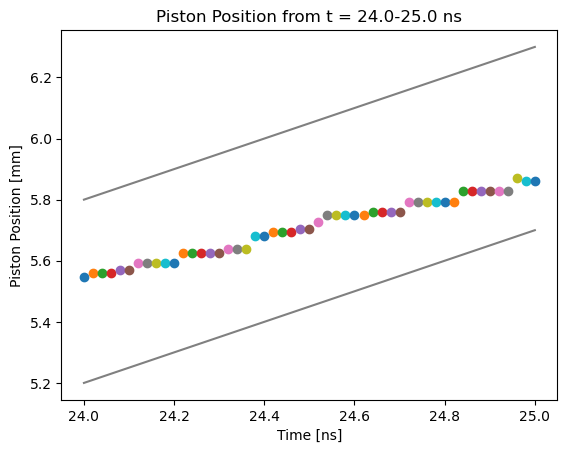

(None, None, None)

In [10]:
times_piston = []
pos_piston = []
lo_piston = []

initial_piston = 1.5
pos, lo = afn.get_averaged_lineouts(x_common, times_avg_1516, pos_avg_1516, lineouts_avg_1516, initial_piston)
pos_piston.append(pos), lo_piston.append(lo), times_piston.append(np.average(times_avg_1516))

initial_piston = 2
pos, lo = afn.get_averaged_lineouts(x_common, times_avg_1617, pos_avg_1617, lineouts_avg_1617, initial_piston)
pos_piston.append(pos), lo_piston.append(lo), times_piston.append(np.average(times_avg_1617))

initial_piston = 2.5
pos, lo = afn.get_averaged_lineouts(x_common, times_avg_1718, pos_avg_1718, lineouts_avg_1718, initial_piston)
pos_piston.append(pos), lo_piston.append(lo), times_piston.append(np.average(times_avg_1718))

initial_piston = 3
pos, lo = afn.get_averaged_lineouts(x_common, times_avg_1819, pos_avg_1819, lineouts_avg_1819, initial_piston)
pos_piston.append(pos), lo_piston.append(lo), times_piston.append(np.average(times_avg_1819))

initial_piston = 3.5
pos, lo = afn.get_averaged_lineouts(x_common, times_avg_1920, pos_avg_1920, lineouts_avg_1920, initial_piston)
pos_piston.append(pos), lo_piston.append(lo), times_piston.append(np.average(times_avg_1920))

initial_piston = 4
pos, lo = afn.get_averaged_lineouts(x_common, times_avg_2021, pos_avg_2021, lineouts_avg_2021, initial_piston)
pos_piston.append(pos), lo_piston.append(lo), times_piston.append(np.average(times_avg_2021))

initial_piston = 4.4
pos, lo = afn.get_averaged_lineouts(x_common, times_avg_2122, pos_avg_2122, lineouts_avg_2122, initial_piston)
pos_piston.append(pos), lo_piston.append(lo), times_piston.append(np.average(times_avg_2122))

initial_piston = 4.8
pos, lo = afn.get_averaged_lineouts(x_common, times_avg_2223, pos_avg_2223, lineouts_avg_2223, initial_piston)
pos_piston.append(pos), lo_piston.append(lo), times_piston.append(np.average(times_avg_2223))

initial_piston = 5.1
pos, lo = afn.get_averaged_lineouts(x_common, times_avg_2324, pos_avg_2324, lineouts_avg_2324, initial_piston)
pos_piston.append(pos), lo_piston.append(lo), times_piston.append(np.average(times_avg_2324))

initial_piston = 5.5
pos, lo = afn.get_averaged_lineouts(x_common, times_avg_2425, pos_avg_2425, lineouts_avg_2425, initial_piston)
pos_piston.append(pos), lo_piston.append(lo), times_piston.append(np.average(times_avg_2425))

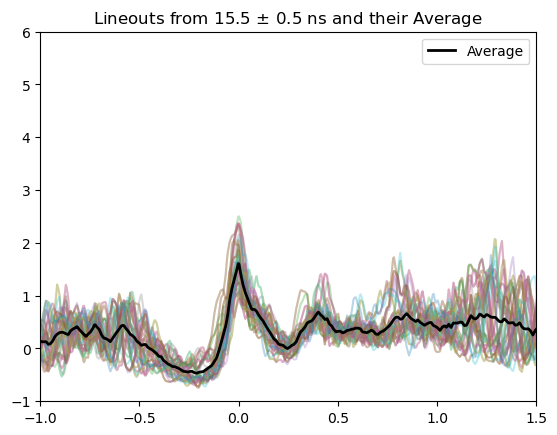

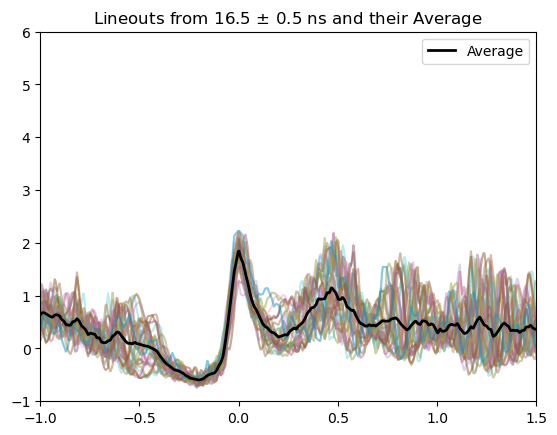

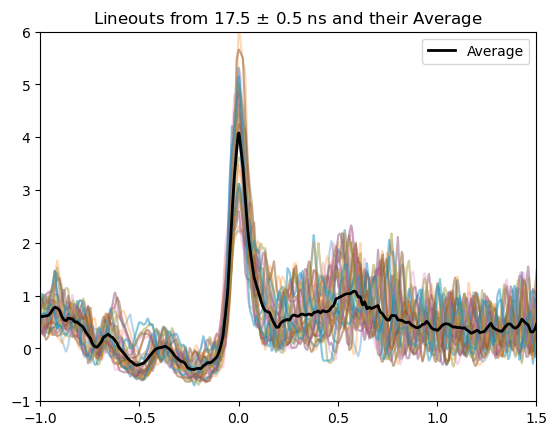

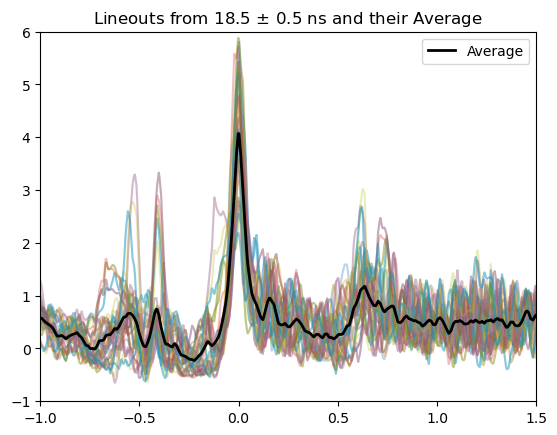

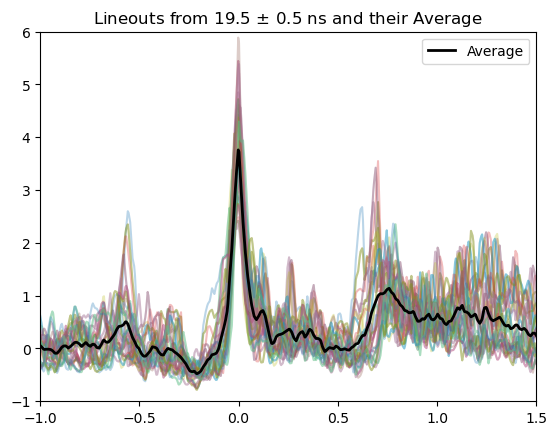

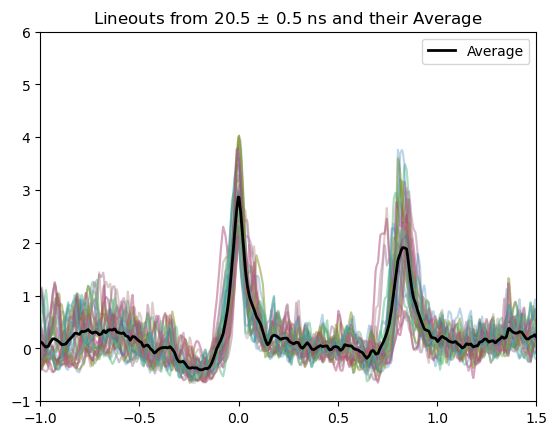

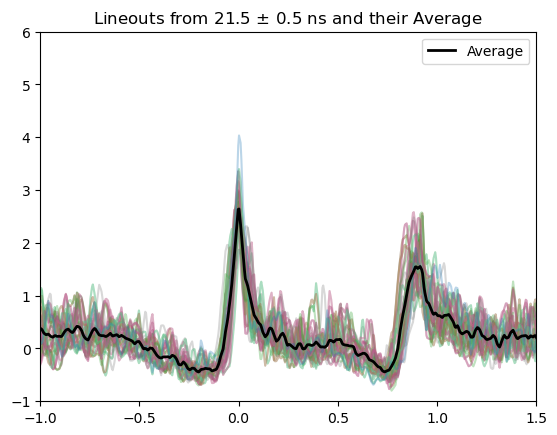

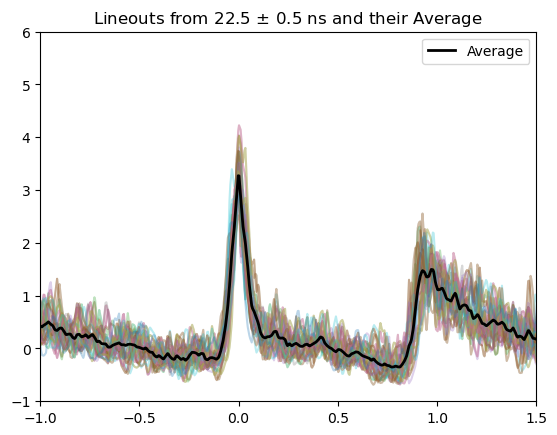

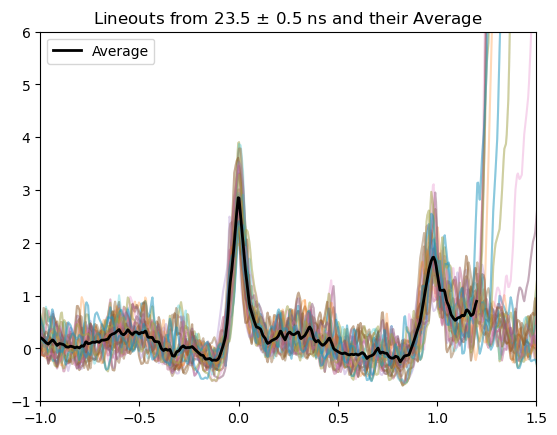

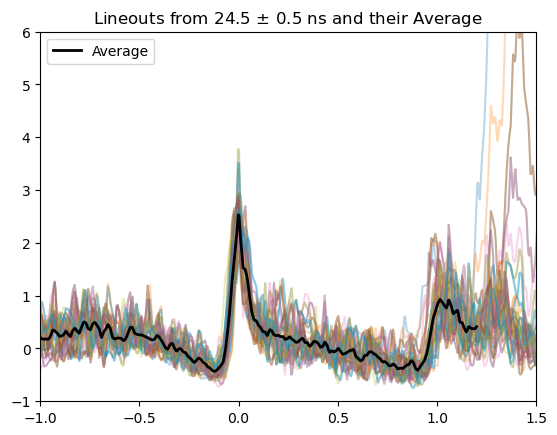

In [11]:
averages_piston = []
for i in range(len(times_piston)):
    n_lines = len(lo_piston[i])
    for j in range(n_lines):
        plt.plot(x_common, lo_piston[i][j], alpha=0.3)
    
    average_lo = np.mean(lo_piston[i][:n_lines], axis=0)
    x = x_common
    
    if times_piston[i] > 23:
        mask = x_common < 1.2
        average_lo = average_lo[mask]
        x = x_common[mask]
        x_cut = x
    averages_piston.append(average_lo)
    
    plt.plot(x, average_lo, color='black', linewidth=2, label='Average')
    plt.xlim(-1,1.5)
    plt.ylim(-1,6)
    plt.title(f'Lineouts from {times_piston[i]} $\pm$ 0.5 ns and their Average')
    plt.legend()
    plt.show()

# Model Shocks

shift: 0.2


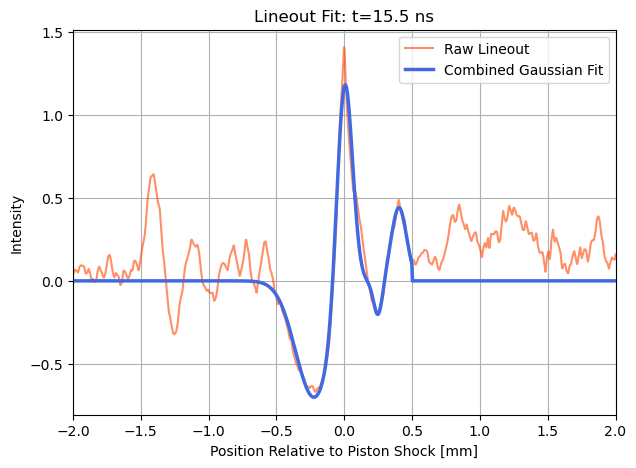

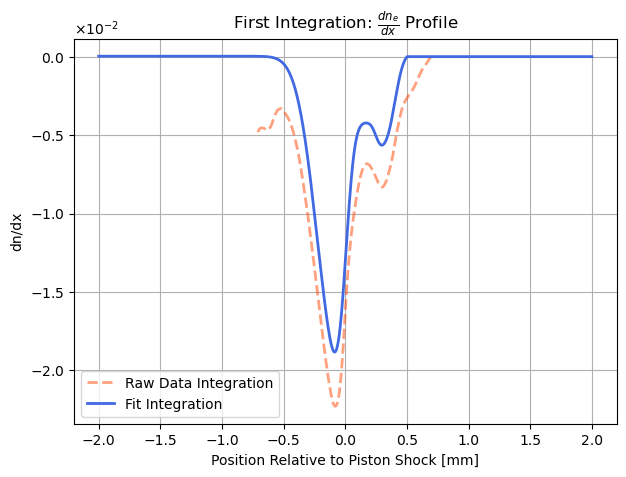

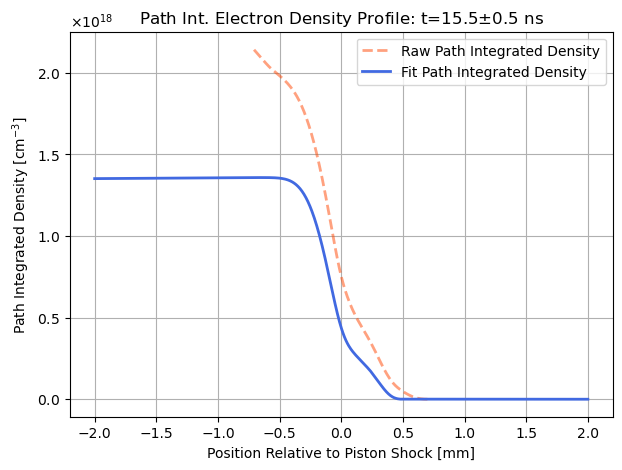

In [12]:
idx = 0
shift = 0.2
print('shift:', shift)

y_raw = averages_piston[idx] - shift
sort_descending = np.argsort(x_common)[::-1] 

x_data = x_common[sort_descending]
y_data = y_raw[sort_descending]

piston_lim = [-0.8, 0.4]
mag_lim = [0.1, 0.5]

afn.plot_shock_density(x_data, y_data, piston_lim, mag_lim, times_piston[idx])

shift: 0.322


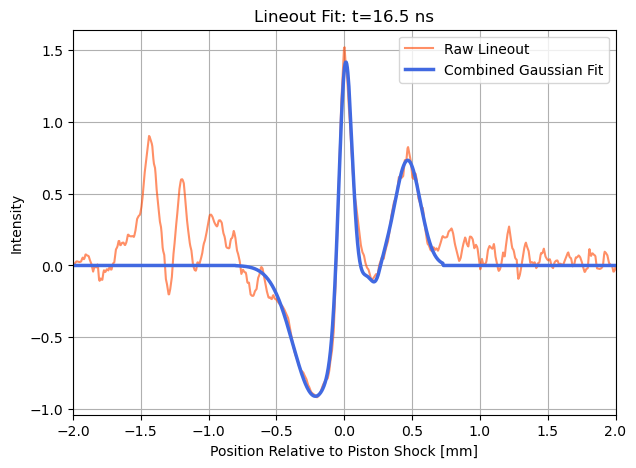

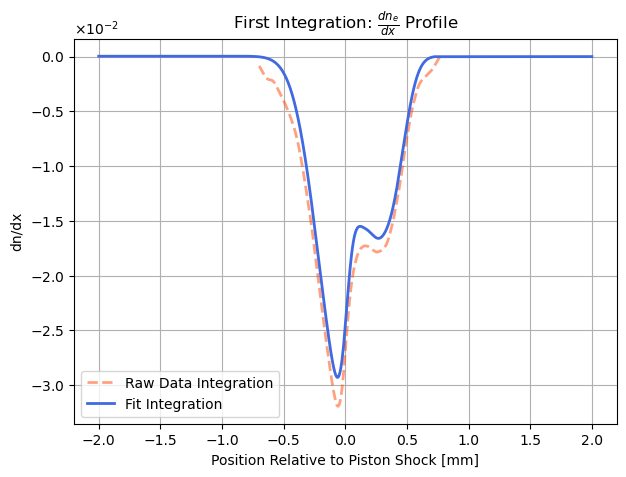

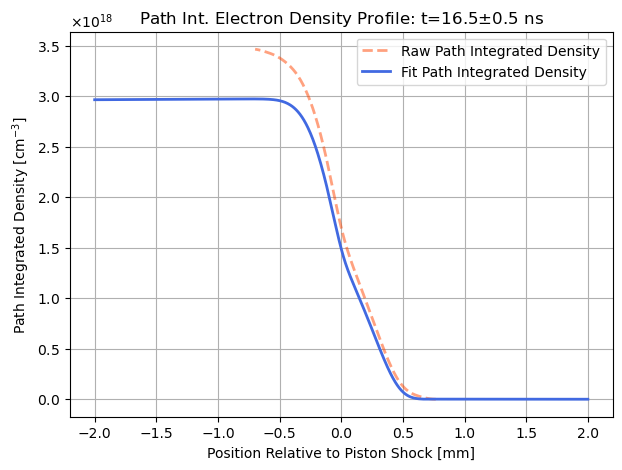

In [13]:
idx = 1
shift = 0.322
print('shift:', shift)

y_raw = averages_piston[idx] - shift
sort_descending = np.argsort(x_common)[::-1] 

x_data = x_common[sort_descending]
y_data = y_raw[sort_descending]

piston_lim = [-0.8, 0.4]
mag_lim = [0.1, 0.73]

afn.plot_shock_density(x_data, y_data, piston_lim, mag_lim, times_piston[idx])

shift: 0.515


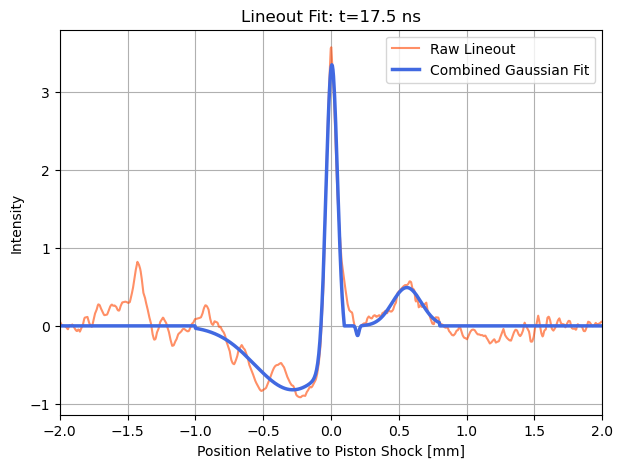

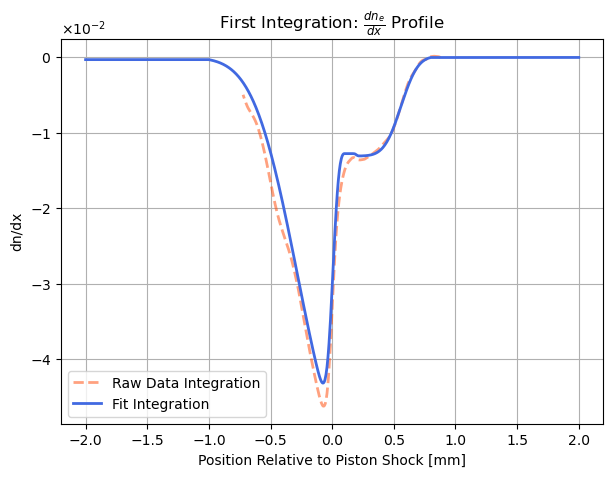

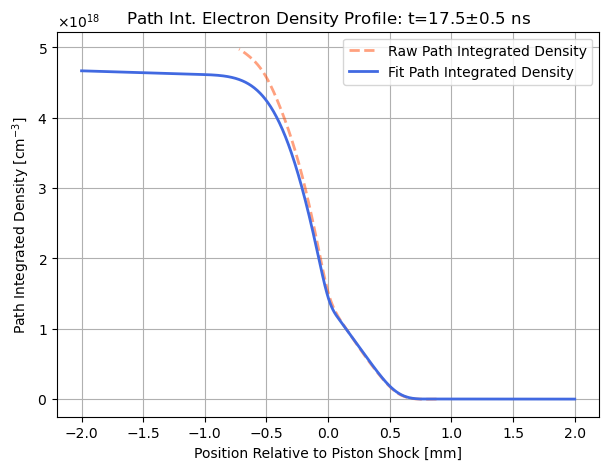

In [14]:
idx = 2
shift = 0.515
print('shift:', shift)

y_raw = averages_piston[idx] - shift
sort_descending = np.argsort(x_common)[::-1] 

x_data = x_common[sort_descending]
y_data = y_raw[sort_descending]

piston_lim = [-1, 0.095]
mag_lim = [0.1, 0.8]

afn.plot_shock_density(x_data, y_data, piston_lim, mag_lim, times_piston[idx])

shift: 0.6


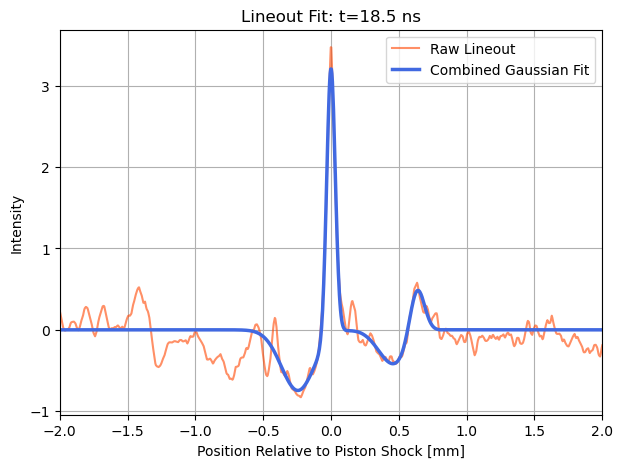

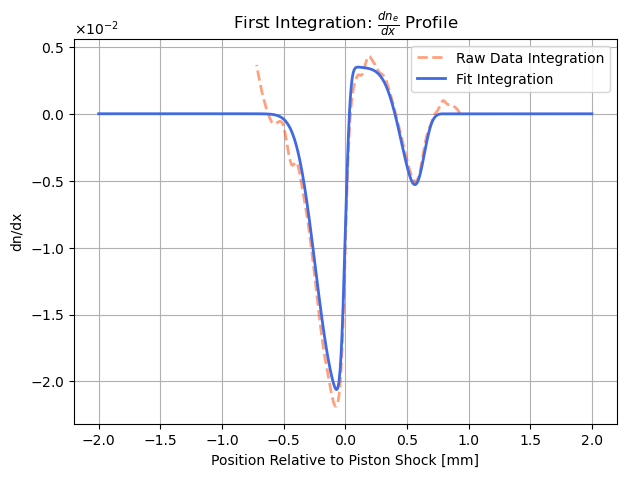

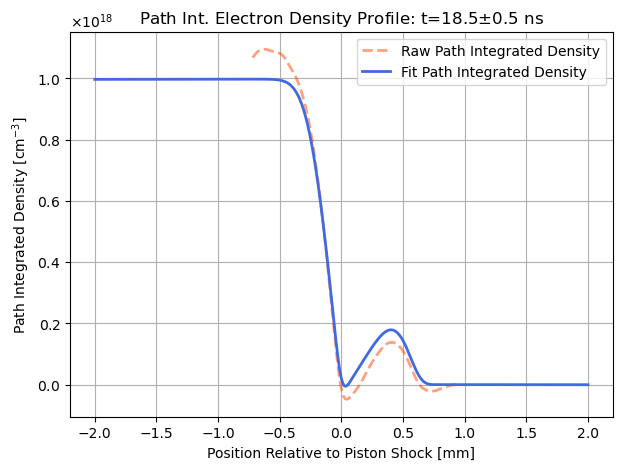

In [15]:
idx = 3
shift = 0.6
print('shift:', shift)

y_raw = averages_piston[idx] - shift
sort_descending = np.argsort(x_common)[::-1] 

x_data = x_common[sort_descending]
y_data = y_raw[sort_descending]

piston_lim = [-0.8, 0.2]
mag_lim = [0.1, 1]

afn.plot_shock_density(x_data, y_data, piston_lim, mag_lim, times_piston[idx])

shift: 0.383


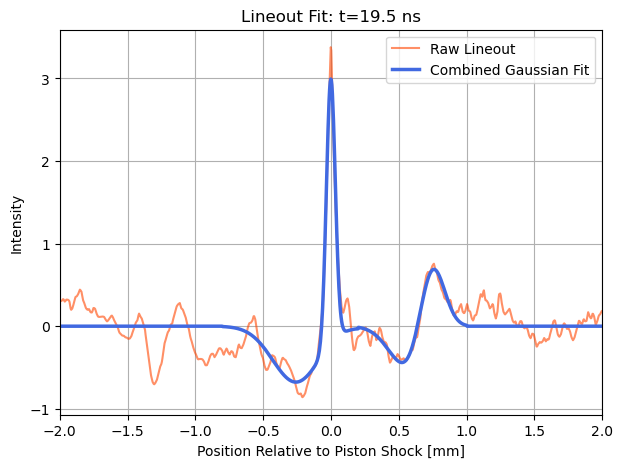

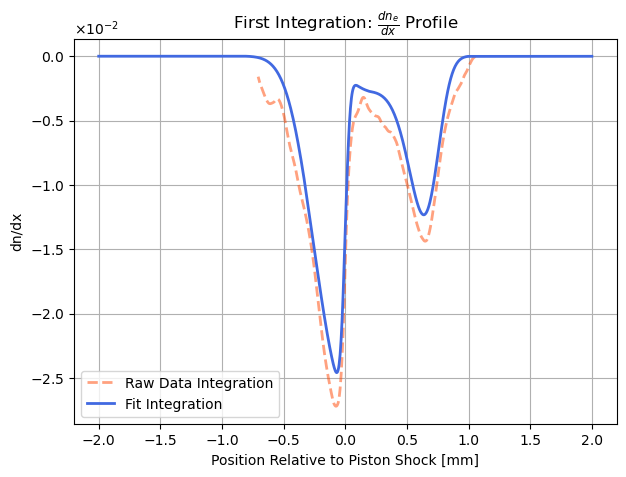

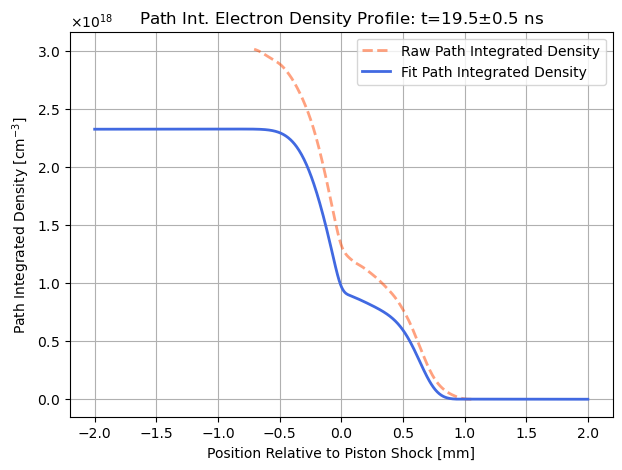

In [16]:
idx = 4
shift = 0.383
print('shift:', shift)

y_raw = averages_piston[idx] - shift
sort_descending = np.argsort(x_common)[::-1] 

x_data = x_common[sort_descending]
y_data = y_raw[sort_descending]

piston_lim = [-0.8, 0.2]
mag_lim = [0.1, 1]

afn.plot_shock_density(x_data, y_data, piston_lim, mag_lim, times_piston[idx])

shift: 0.303


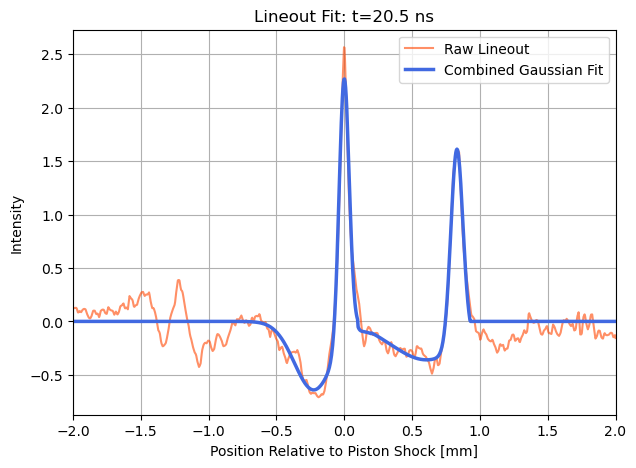

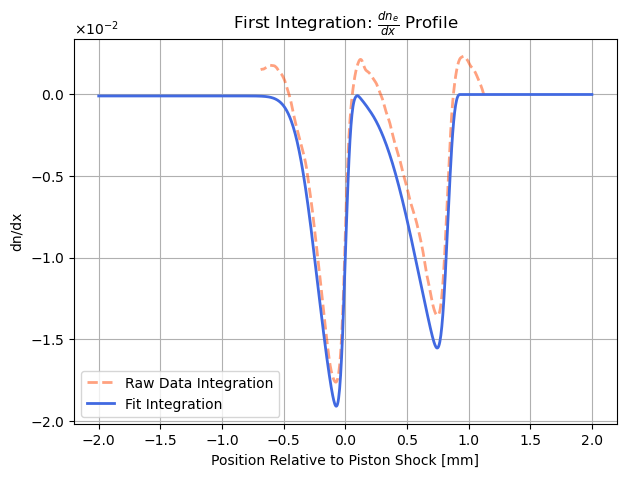

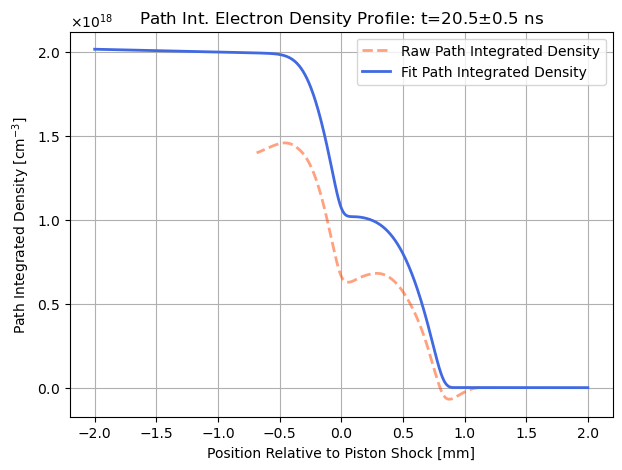

In [17]:
idx = 5 

shift = 0.303
print('shift:', shift)

y_raw = averages_piston[idx] - shift
sort_descending = np.argsort(x_common)[::-1] 

x_data = x_common[sort_descending]
y_data = y_raw[sort_descending]

piston_lim = [-0.8, 0.2]
mag_lim = [0.1, 0.93]

afn.plot_shock_density(x_data, y_data, piston_lim, mag_lim, times_piston[idx])

shift: 0.25


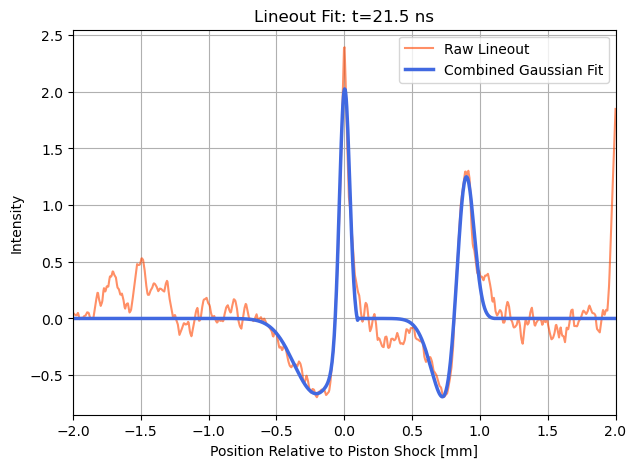

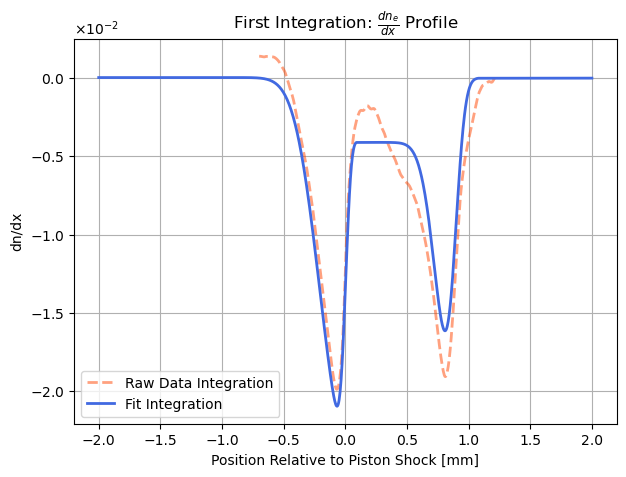

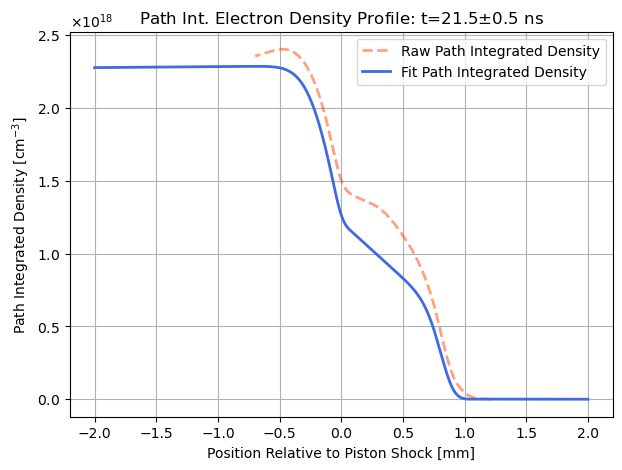

In [18]:
idx = 6

shift = 0.25
print('shift:', shift)

y_raw = averages_piston[idx] - shift
sort_descending = np.argsort(x_common)[::-1] 

x_data = x_common[sort_descending]
y_data = y_raw[sort_descending]

piston_lim = [-0.8, 0.1]
mag_lim = [0.1, 1.2]

afn.plot_shock_density(x_data, y_data, piston_lim, mag_lim, times_piston[idx])

shift: 0.297


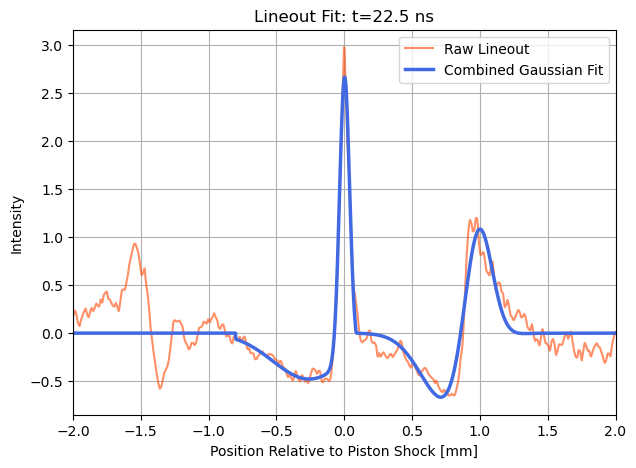

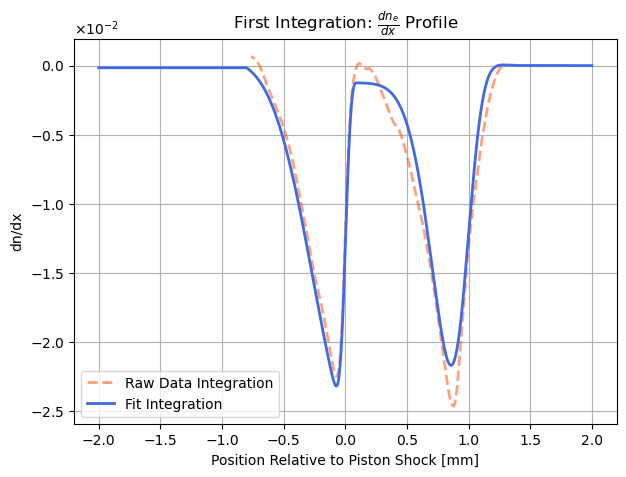

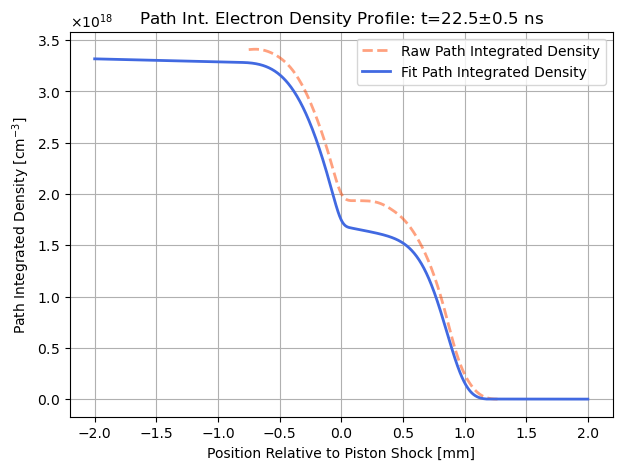

In [19]:
idx = 7

shift = 0.297
print('shift:', shift)

y_raw = averages_piston[idx] - shift
sort_descending = np.argsort(x_common)[::-1] 

x_data = x_common[sort_descending]
y_data = y_raw[sort_descending]

piston_lim = [-0.8, 0.09]
mag_lim = [0.1, 1.5]

afn.plot_shock_density(x_data, y_data, piston_lim, mag_lim, times_piston[idx])

shift: 0.35


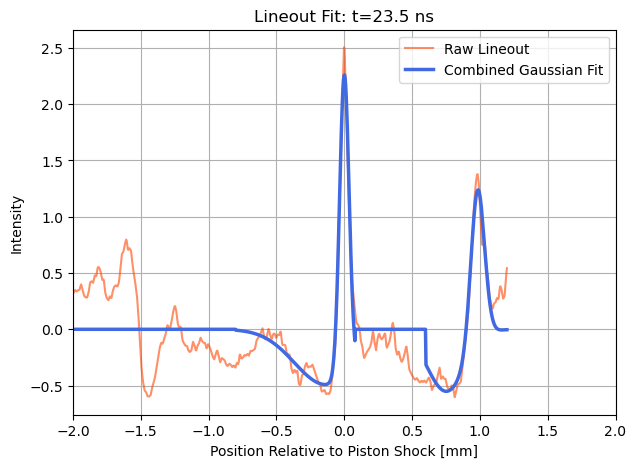

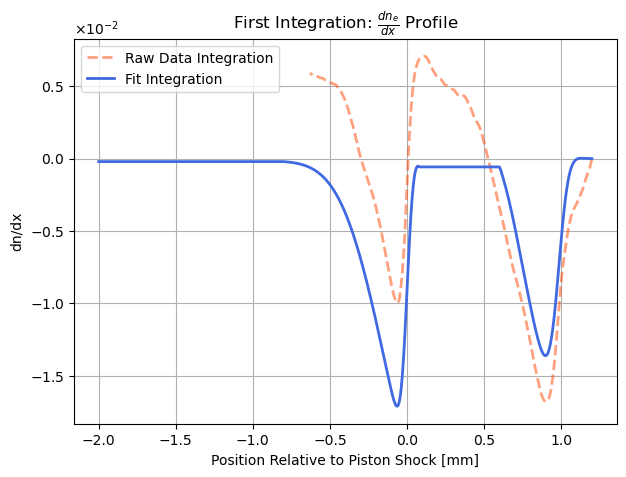

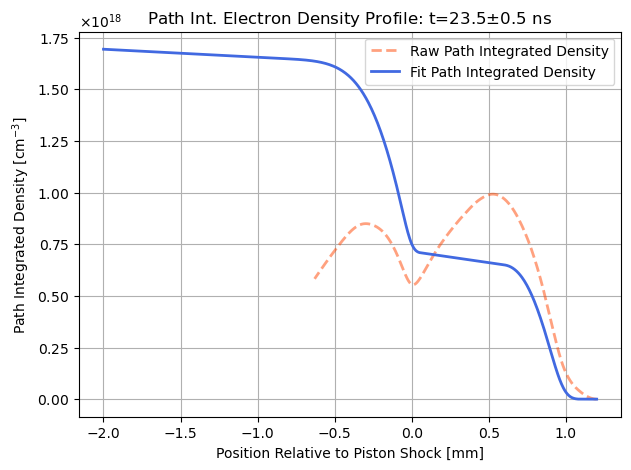

In [20]:
idx = 8

shift = 0.35
print('shift:', shift)

y_raw = averages_piston[idx] - shift
sort_descending = np.argsort(x_cut)[::-1] 

x_data = x_cut[sort_descending]
y_data = y_raw[sort_descending]

piston_lim = [-0.8, 0.08]
mag_lim = [0.48, 1.5]
mag_lim = [0.6, 1.5]

afn.plot_shock_density(x_data, y_data, piston_lim, mag_lim, times_piston[idx])

shift: 0.147


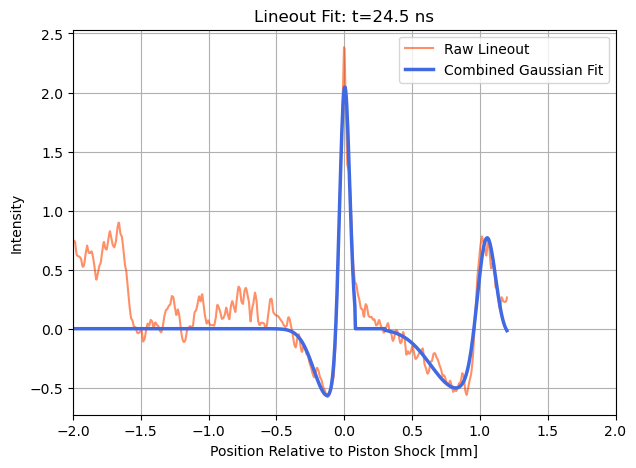

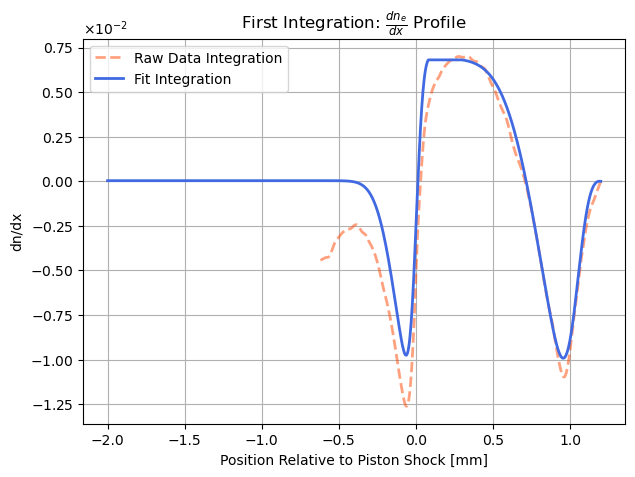

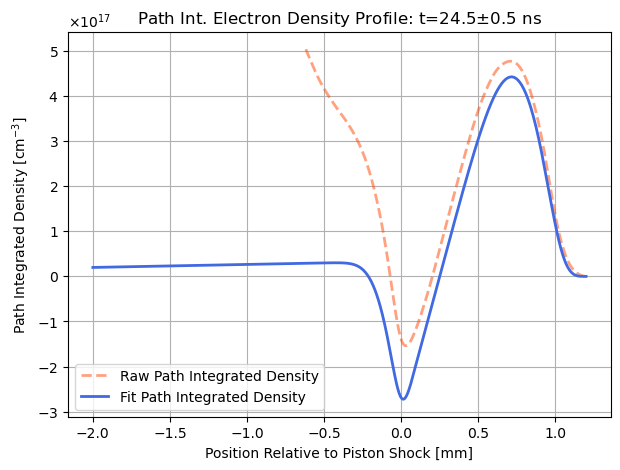

In [21]:
idx = 9

shift = 0.147
print('shift:', shift)

y_raw = averages_piston[idx] - shift
sort_descending = np.argsort(x_cut)[::-1] 

x_data = x_cut[sort_descending]
y_data = y_raw[sort_descending]

piston_lim = [-0.8, 0.08]
mag_lim = [0.3, 1.5]

afn.plot_shock_density(x_data, y_data, piston_lim, mag_lim, times_piston[idx])

In [22]:
all_peaks = []
peak_times = []

# t = 15
i = 5
piston_lims = [0.5, 2]
mag_lims = [1.5, 2]
peaks_15 = afn.find_shock_positions(pos_shock[i], lineouts_shock[i], times_shock[i], piston_lims, mag_lims)
all_peaks.append(peaks_15)
peak_times.append(times_shock[i])

# t = 16
i = 6
piston_lims = [1, 3]
mag_lims = [2.3, 2.55]
peaks_16 = afn.find_shock_positions(pos_shock[i], lineouts_shock[i], times_shock[i], piston_lims, mag_lims)
all_peaks.append(peaks_16)
peak_times.append(times_shock[i])

i = 7
piston_lims = [1, 4]
mag_lims = [2.8, 3.05]
peaks_17 = afn.find_shock_positions(pos_shock[i], lineouts_shock[i], times_shock[i], piston_lims, mag_lims)
all_peaks.append(peaks_17)
peak_times.append(times_shock[i])

i = 8
piston_lims = [1, 4]
mag_lims = [3.4, 4]
peaks_18 = afn.find_shock_positions(pos_shock[i], lineouts_shock[i], times_shock[i], piston_lims, mag_lims)
all_peaks.append(peaks_18)
peak_times.append(times_shock[i])

i = 9
piston_lims = [3.2, 4]
mag_lims = [3.7, 4.5]
peaks_19 = afn.find_shock_positions(pos_shock[i], lineouts_shock[i], times_shock[i], piston_lims, mag_lims)
all_peaks.append(peaks_19)
peak_times.append(times_shock[i])

i = 10
piston_lims = [3.2, 4]
mag_lims = [4.5, 5]
peaks_20 = afn.find_shock_positions(pos_shock[i], lineouts_shock[i], times_shock[i], piston_lims, mag_lims)
all_peaks.append(peaks_20)
peak_times.append(times_shock[i])

i = 11
piston_lims = [4, 5]
mag_lims = [5, 6]
peaks_21 = afn.find_shock_positions(pos_shock[i], lineouts_shock[i], times_shock[i], piston_lims, mag_lims)
all_peaks.append(peaks_21)
peak_times.append(times_shock[i])

i = 12
piston_lims = [4, 5]
mag_lims = [5, 6]
peaks_22 = afn.find_shock_positions(pos_shock[i], lineouts_shock[i], times_shock[i], piston_lims, mag_lims)
all_peaks.append(peaks_22)
peak_times.append(times_shock[i])

i = 13
piston_lims = [4.5, 5.5]
mag_lims = [5.5, 6.5]
peaks_23 = afn.find_shock_positions(pos_shock[i], lineouts_shock[i], times_shock[i], piston_lims, mag_lims)
all_peaks.append(peaks_23)
peak_times.append(times_shock[i])

i = 14
piston_lims = [4.5, 5.5]
mag_lims = [6, 6.7]
peaks_24 = afn.find_shock_positions(pos_shock[i], lineouts_shock[i], times_shock[i], piston_lims, mag_lims)
all_peaks.append(peaks_24)
peak_times.append(times_shock[i])

i = 15
piston_lims = [5, 6]
mag_lims = [6, 7]
peaks_25 = afn.find_shock_positions(pos_shock[i], lineouts_shock[i], times_shock[i], piston_lims, mag_lims)
all_peaks.append(peaks_25)
peak_times.append(times_shock[i])

i = 17
piston_lims = [6.4, 6.5]
mag_lims = [7.4, 8]
peaks_26 = afn.find_shock_positions(pos_shock[i], lineouts_shock[i], times_shock[i], piston_lims, mag_lims)
all_peaks.append(peaks_26)
peak_times.append(times_shock[i])

all_peaks = np.array(all_peaks)

<Figure size 640x480 with 0 Axes>

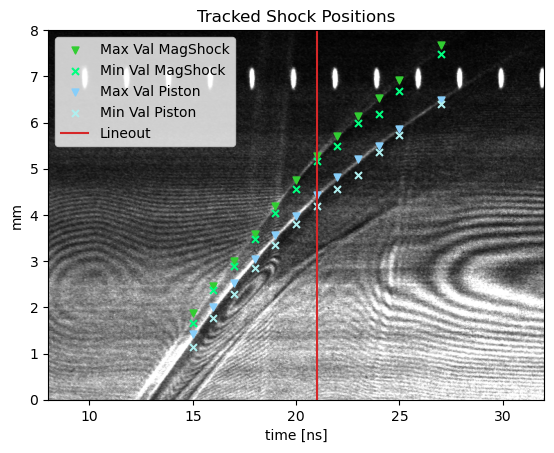

In [22]:
plt.imshow(streak, cmap = 'grey', extent=ext, aspect='auto')
plt.clim(0, cmax)
plt.xlabel('time [ns]')
plt.ylabel('mm')

plt.scatter(peak_times, all_peaks[:,3], color = 'limegreen', s = 25, label = 'Max Val MagShock', marker = 'v')
plt.scatter(peak_times, all_peaks[:,2], color = 'springgreen', s = 25, label = 'Min Val MagShock', marker = 'x')
plt.scatter(peak_times, all_peaks[:,1], color = 'lightskyblue', s = 25, label = 'Max Val Piston', marker = 'v')
plt.scatter(peak_times, all_peaks[:,0], color = 'paleturquoise', s = 25, label = 'Min Val Piston', marker = 'x')

plt.axvline(21, color = 'tab:red', label = 'Lineout')

plt.xlim(8, 32)
plt.ylim(0, 8)
# plt.ylim(1, 5)
plt.legend(loc = 'upper left')
plt.title('Tracked Shock Positions')

plt.savefig('streak_images/zfs/shock_positions_img_ROI', bbox_inches = 'tight')

In [23]:
rel_pos_magshock = []
speeds_magshock = []
for i in range(len(peak_times)-1):
    j = i+1
    rel = all_peaks[j,3] - all_peaks[j-1,3]
    rel_pos_magshock.append(peak_times[j]) 
    speed_mm_ns = rel/(peak_times[j]-peak_times[j-1])
    speed_km_s = speed_mm_ns * (1e-6)/(1e-9)
    speeds_magshock.append(speed_km_s)
    print(peak_times[j])
    print(speed_km_s)

rel_pos_piston = []
speeds_piston = []
for i in range(len(peak_times)-1):
    j = i+1
    rel = all_peaks[j,1] - all_peaks[j-1,1]
    rel_pos_piston.append(peak_times[j]) 
    speed_mm_ns = rel/(peak_times[j]-peak_times[j-1])
    speed_km_s = speed_mm_ns * (1e-6)/(1e-9)
    speeds_piston.append(speed_km_s)

16.0
591.0794053607659
17.0
546.4696389184418
18.0
579.9269637501844
19.0
613.3842885819258
20.0
557.6220805290228
21.0
524.1647556972823
22.0
423.79278120205737
23.0
434.94522281263846
24.0
390.335456370316
25.0
390.335456370316
27.0
373.6067939544449


[15.5, 16.5, 17.5, 18.5, 19.5, 20.5, 21.5, 22.5, 23.5, 24.5, 26]


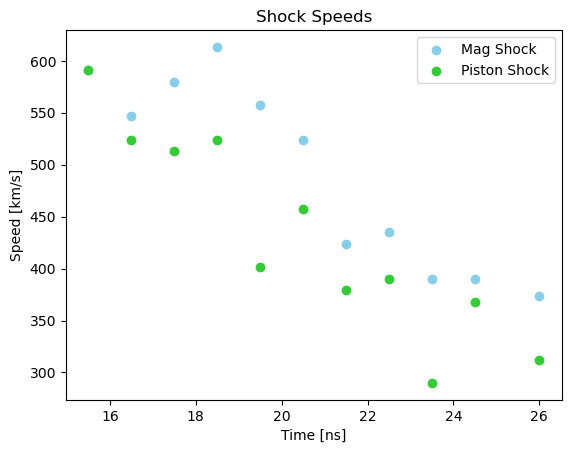

In [24]:
times_plot = [15.5, 16.5, 17.5, 18.5, 19.5, 20.5, 21.5, 22.5, 23.5, 24.5, 26]
print(times_plot)
plt.scatter(times_plot, speeds_magshock, label = 'Mag Shock', color = 'skyblue')
plt.scatter(times_plot, speeds_piston, label = 'Piston Shock', color = 'limegreen')
plt.legend()
plt.title('Shock Speeds')
plt.ylabel('Speed [km/s]')
plt.xlabel('Time [ns]')
plt.savefig('streak_images/zfs/speeds', bbox_inches = 'tight')